 //explicacion del dataset y grupo  

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

// Importacion del data set

In [3]:
dataset = pd.read_csv('../../dataset/listings.csv')
dataset.info(verbose=True, show_counts=True)
type(dataset)

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  str    
 9   host_id                                       29685 non-null  int64  
 1

pandas.DataFrame

In [4]:
nulos = dataset[['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood','neighbourhood_group_cleansed', 'calendar_updated', 'instant_bookable']]
nulos.head(15)
#"host_since", "host_response_time", "host_response_rate", "host_acceptance_rate", "host_thumbnail_url", "host_neighbourhood", "host_total_listings_count", "host_verifications neighbourhood","neighbourhood_group_cleansed", "calendar_updated", "instant_bookable"

,neighborhood_overview,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_thumbnail_url,host_neighbourhood,host_total_listings_count,host_verifications,neighbourhood,neighbourhood_group_cleansed,calendar_updated,instant_bookable
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


a priori vemos que las siguientes variables no presentan valores, es decir, estan vacías (codigo de abajo).


In [5]:

vacias = dataset.columns[dataset.isna().all()]
print(len(vacias), "columnas vacías:")
for col in vacias:
    print("-", col)

13 columnas vacías:
- neighborhood_overview
- host_since
- host_response_time
- host_response_rate
- host_acceptance_rate
- host_thumbnail_url
- host_neighbourhood
- host_total_listings_count
- host_verifications
- neighbourhood
- neighbourhood_group_cleansed
- calendar_updated
- instant_bookable


//introducción, mostrar tablas y contar que se borra y la tabla desp de la limpieza. 
Empezamos por las columnas vacias

In [6]:
dataset_limpio = dataset.drop(columns=vacias)
print(dataset.shape, "->", dataset_limpio.shape)
print("\n")
dataset_limpio.info()

(29685, 90) -> (29685, 77)


<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   picture_url                                   29684 non-null  str    
 8   host_id                                       29685 non-null  int64  
 9   host_url                                   

In [7]:
dataset_limpio.describe() #describe no toma en cuenta los string, por eso las 48 cols

,id,scrape_id,host_id,host_profile_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_listings_count,latitude,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.968500e+04,2.968500e+04,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,...,25957.000000,25957.000000,25957.000000,25957.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,25957.000000
mean,9.329954e+17,2.026063e+13,1.081103e+16,1.476728e+18,7.506687,5.532727,5.323362,5.461142,19.602964,-34.592114,...,4.742028,4.869180,4.862890,4.874793,4.740904,15.194240,14.214654,0.701937,0.057773,1.481166
std,5.838355e+17,0.000000e+00,1.347071e+17,3.962312e+16,4.083517,3.376887,4.046868,3.296444,44.760560,0.017920,...,0.371037,0.291209,0.304637,0.244150,0.375315,32.782011,32.632849,3.608907,0.735822,1.640487
min,1.150800e+04,2.026063e+13,1.342600e+04,1.462507e+18,0.000000,0.000000,0.000000,0.000000,0.000000,-34.690056,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,6.233293e+17,2.026063e+13,3.506745e+07,1.462945e+18,4.000000,3.000000,2.000000,3.000000,1.000000,-34.603396,...,4.670000,4.850000,4.850000,4.850000,4.680000,1.000000,1.000000,0.000000,0.000000,0.370000
50%,1.046350e+18,2.026063e+13,1.585246e+08,1.467135e+18,8.000000,5.000000,4.000000,5.000000,3.000000,-34.591459,...,4.830000,4.950000,4.950000,4.940000,4.830000,3.000000,2.000000,0.000000,0.000000,0.980000
75%,1.431417e+18,2.026063e+13,4.644293e+08,1.470093e+18,11.000000,8.000000,8.000000,8.000000,16.000000,-34.581430,...,4.950000,5.000000,5.000000,5.000000,4.940000,12.000000,10.000000,0.000000,0.000000,2.050000
max,1.717830e+18,2.026063e+13,1.716955e+18,1.716967e+18,17.000000,11.000000,15.000000,11.000000,1375.000000,-34.534980,...,5.000000,5.000000,5.000000,5.000000,5.000000,208.000000,208.000000,52.000000,18.000000,41.660000


In [8]:
dataset_limpio.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,54019695,https://www.airbnb.com/rooms/54019695,20260629030533,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,https://a0.muscache.com/pictures/miso/Hosting-...,298874610,https://www.airbnb.com/users/show/298874610,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
1,41720307,https://www.airbnb.com/rooms/41720307,20260629030533,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,https://a0.muscache.com/pictures/37e687e2-2587...,220409424,https://www.airbnb.com/users/show/220409424,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
2,1090530711732696379,https://www.airbnb.com/rooms/1090530711732696379,20260629030533,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,https://a0.muscache.com/pictures/3adbe27a-af59...,488443857,https://www.airbnb.com/users/show/488443857,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
3,1482653002662185299,https://www.airbnb.com/rooms/1482653002662185299,20260629030533,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",https://a0.muscache.com/pictures/hosting/Hosti...,283840529,https://www.airbnb.com/users/show/283840529,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
4,1046394538968941382,https://www.airbnb.com/rooms/1046394538968941382,20260629030533,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,https://a0.muscache.com/pictures/hosting/Hosti...,550970409,https://www.airbnb.com/users/show/550970409,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


Ahora siguen las variables que no nos dicen nada.


In [9]:
por_host = dataset_limpio.groupby("host_has_profile_pic")["host_id"].nunique()
porcentaje = (por_host / por_host.sum() * 100).round(1)

display(pd.DataFrame({"hosts": por_host, "%": porcentaje}))



,hosts,%
host_has_profile_pic,,
f,826,5.7
t,13730,94.3


Con esto vemos que la variable (host_has_profile_pic) no contiene informacion relevante, por eso puede ser borrada.

In [10]:
scrape = dataset_limpio["scrape_id"].nunique()
scrape

1

 Vemos que con la variable scrape id, no tenemos info relevante (ya que hay un unico scrapeo de los datos)

In [11]:
dataset_limpio = dataset_limpio.set_index("id")
a_borrar = ["listing_url", "scrape_id", "picture_url", "host_url",
            "host_picture_url", "host_has_profile_pic", "host_thumbnail_url"]

ya_borradas = [c for c in a_borrar if c not in dataset_limpio.columns]
print("Ya no estaban:", ya_borradas)

dataset_limpio = dataset_limpio.drop(columns=[c for c in a_borrar if c in dataset_limpio.columns])
print(dataset_limpio.shape)
dataset_limpio

Ya no estaban: ['host_thumbnail_url']
(29685, 70)


,last_scraped,source,name,description,host_id,host_profile_id,host_profile_url,host_name,hosts_time_as_user_years,hosts_time_as_user_months,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
id,,,,,,,,,,,,,,,,,,,,,
54019695,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,298874610,1469536348265366895,https://www.airbnb.com/users/profile/146953634...,Pablo,6,9,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
41720307,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,220409424,1463206751662853765,https://www.airbnb.com/users/profile/146320675...,Monica,7,8,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
1090530711732696379,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,488443857,1470198261120530992,https://www.airbnb.com/users/profile/147019826...,Mathi,3,7,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
1482653002662185299,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",283840529,1469486631712739967,https://www.airbnb.com/users/profile/146948663...,Liliana,6,10,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
1046394538968941382,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,550970409,1470463634022740655,https://www.airbnb.com/users/profile/147046363...,Braian,2,6,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994022693284854325,2026-07-02,previous scrape,Lumiere Fair apparemment,Lumiere Fair has a modern and bright design th...,124702396,1468258412487155546,https://www.airbnb.com/users/profile/146825841...,Nancy,9,2,...,4.86,4.43,4.71,4.86,NaN,3,3,0,0,0.21
1016061449243279308,2026-07-02,previous scrape,Charming Modern Studio in Caballito,Bright and stylish modern studio in the heart ...,344599,1462516210018566099,https://www.airbnb.com/users/profile/146251621...,Welcome BA,15,5,...,4.90,4.85,4.90,4.84,NaN,31,31,0,0,2.85
1055203909942066000,2026-07-02,previous scrape,Lovely Moldes,"Kick back and relax in this calm, stylish space.",552774318,1470470371718015421,https://www.airbnb.com/users/profile/147047037...,Jorge Enrique,2,6,...,4.91,4.94,4.97,4.94,NaN,1,1,0,0,1.14


In [12]:
print(dataset_limpio.isna().sum())

last_scraped                                       0
source                                             0
name                                               0
description                                      768
host_id                                            0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               3728
Length: 70, dtype: int64


In [13]:
dataset_limpio["description"].value_counts()

description
Keep it simple at this peaceful and centrally-located place.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 148
MOT is the leading agency for short term rentals in Buenos Aires and Mendoza. We also offer amazing monthly deals for long term stays. Contact us for further information!                                                                                                                                                                                                                                                                 

Vemos que quiza las descripciones no nos dicen muchos, aunque las podriamos utilizar para conocer que cantidad de publicaciones tienen descripcio vs. las que no

In [14]:
dataset_limpio["minimum_nights"].describe()

count    29682.000000
mean         4.951722
std         18.114840
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        730.000000
Name: minimum_nights, dtype: float64

In [15]:
dataset_limpio["room_type"].value_counts()

room_type
Entire home/apt    26790
Private room        2616
Hotel room           141
Shared room          138
Name: count, dtype: int64

// depuracion de la base (variables no utilizables,columnas enteramente nulas..)

//UNIVARIADAS 

### Para comenzar la validacion de las Hipotesis A y B, primero vamos, por cada una de ellas, a mirar como se comporta la muestra, utilizando distintas herramientos tanto analiticas como graficas.

### Analisis de la hipotesis A (Mas del 60% de la oferta es controlada por agencias multipropiedad, no por personas alquilando su propio hogar)

In [16]:
dfA=dataset_limpio[["host_id", "calculated_host_listings_count"]]
dfA.describe()


,host_id,calculated_host_listings_count
count,2.968500e+04,29685.000000
mean,1.081103e+16,15.194240
std,1.347071e+17,32.782011
min,1.342600e+04,1.000000
25%,3.506745e+07,1.000000
50%,1.585246e+08,3.000000
75%,4.644293e+08,12.000000
max,1.716955e+18,208.000000


In [17]:
dfA.count()

host_id                           29685
calculated_host_listings_count    29685
dtype: int64

In [18]:
cuenta = dfA["host_id"].value_counts()
filtered = cuenta[cuenta > 1]
print("Multipropiedad: ", filtered.count(), "Personales: ", cuenta.count()-filtered.count())

Multipropiedad:  3748 Personales:  10808


De entrada, vemos que la cantidad de listadores con mas de 1 propiedad en dispocicion es casi un tercio de las propiedaes alquiladas por sus propios dueños. Esto aun no nos indica nada, pero teniendo en cuenta que hay aproximadamente 25000 publicaciones, sabemos que ~10000 son de propietario unico, por ende menor.

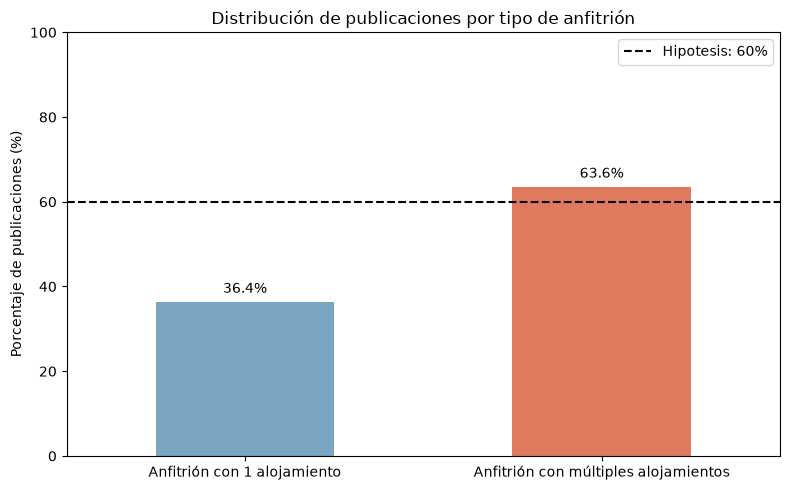

In [19]:
# Porcentaje de publicaciones según si el anfitrión ofrece más de un alojamiento
cuenta = dfA["host_id"].value_counts()
publicaciones = pd.Series({
    "Anfitrión con 1 alojamiento": cuenta[cuenta == 1].sum(),
    "Anfitrión con múltiples alojamientos": cuenta[cuenta > 1].sum(),
})
porcentaje_publicaciones = publicaciones / publicaciones.sum() * 100

#Porcentaje_publicaciones consta con el porcentaje real de publicaciones por sobre la cantidad de publicaciones listadas.

ax = porcentaje_publicaciones.plot(kind="bar", figsize=(8, 5), color=["#7aa6c2", "#e07a5f"])
ax.axhline(60, color="black", linestyle="--", linewidth=1.5, label="Hipotesis: 60%")
ax.set_title("Distribución de publicaciones por tipo de anfitrión")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje de publicaciones (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend()

for barra, valor in zip(ax.patches, porcentaje_publicaciones):
    ax.annotate(f"{valor:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")

plt.tight_layout()
plt.show()

### Con este grafico podemos visualizar claramente que la hipotesis se cumple, ya que mas de el 60% de publicaciones listadas son gestionadas por agencias multipropiedad, ahora chequearemos si las cuentas dicen lo mismo.

Airbnb considera como multi-listing aquellos usuarios que tenga 2 O MAS propiedades publicadas, por eso se toma esa inferencia. 

### Ahora vamos a la parte estadistica, planteo de Hipotesis y su validacion veridica.

In [20]:
#Datos obetnidos
total = dfA["host_id"].count()
uni_pub = cuenta[cuenta ==1].sum()
multi_pub = total - uni_pub

print("Total de publicaciones:", total)
print("Publicaciones personales:", uni_pub)
print("Publicaciones de agencia multipropiedad:", multi_pub)

Total de publicaciones: 29685
Publicaciones personales: 10808
Publicaciones de agencia multipropiedad: 18877


## VALIDACION CON TEST

In [21]:
#Tomando como multipropiedad a aquellos publicadores con MAS de 1 publicacion, vamos a hacer encoding para
#definir una nueva columna en el dataset que nos permita identificar a los publicadores de multipropiedad y a los publicadores personales.
 
#Primero haremos encoding para definir con booleanos si el publicador es de multipropiedad o no. Esto da como resultado el analisis de una variable cualitativa nominal dicotomica.
dfA["multipropiedad"] = dfA["host_id"].apply(lambda x: True if x in filtered.index else False)
print(dfA["multipropiedad"].mean())
print(dfA["multipropiedad"].isna().sum())
print(len(dfA))

0.6359103924541014
0
29685


In [22]:
#Frecuencia absoluta
frec_abs = dfA["multipropiedad"].value_counts()

#Frecuencia relativa
frec_rel = dfA["multipropiedad"].value_counts(normalize=True)

#Tabla para poder analizar
tabla = pd.DataFrame({"Categoria": ["Unipropiedad", "Multipropiedad"], "Frecuencia absoluta": frec_abs, "Frecuencia relativa": frec_rel})

print(tabla)
p_sombrero=dfA["multipropiedad"].mean()
print(f"\nProporcion Mmuestral (media p_sombrero): {p_sombrero:.4f} ({p_sombrero*100:.2f}%)")

                     Categoria  Frecuencia absoluta  Frecuencia relativa
multipropiedad                                                          
True              Unipropiedad                18877              0.63591
False           Multipropiedad                10808              0.36409

Proporcion Mmuestral (media p_sombrero): 0.6359 (63.59%)


#### Lo anteriormente calculado ya nos da un pie a que la hipotesis es verdadera, ya que, analiticamente vemos que la media corresponde al ~63.59%

In [23]:
#Test t para comparar la proporcion muestral con la proporcion poblacional (hipotesis nula)
from scipy.stats import ttest_1samp

p0 = 0.6 #Hipotesis nula
t_stat, p_value = ttest_1samp(dfA["multipropiedad"], p0, alternative='greater')

print(f"\nEstadistico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.4e}")



Estadistico t: 12.8582
Valor p: 4.8802e-38


### Con este estadistico confirmamos que la muestra se encuentra casi 13 desviaciones estandar de la hipotesis, por ende, se acepta la hipotesis de >60% y confirmamos que en el mercado de airbnb, mas del 60% de las viviendas publicadas, pertenecen a agentes multipropiedad.

//BIVARIADAS

### ANALISIS Y VALIDACION DE LA HIPOTESIS B)

Hipotesis: Alquilar un espacio entero cuesta, en promedio, mas del doble que alquilar una habitacion privada.


In [24]:
dfB = dataset_limpio[["price", "room_type"]]
dfB

,price,room_type
id,,
54019695,"$86,206.29",Entire home/apt
41720307,"$74,564.86",Entire home/apt
1090530711732696379,"$514,309.14",Entire home/apt
1482653002662185299,"$144,486.00",Entire home/apt
1046394538968941382,"$25,317.00",Private room
...,...,...
994022693284854325,NaN,Entire home/apt
1016061449243279308,NaN,Entire home/apt
1055203909942066000,NaN,Entire home/apt


In [25]:
dfB.isna().sum()

price        1792
room_type       0
dtype: int64

In [26]:
dfB.info()

<class 'pandas.DataFrame'>
Index: 29685 entries, 54019695 to 994057877545566961
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   price      27893 non-null  str  
 1   room_type  29685 non-null  str  
dtypes: str(2)
memory usage: 695.7 KB


In [27]:
dfB["room_type"].value_counts()

room_type
Entire home/apt    26790
Private room        2616
Hotel room           141
Shared room          138
Name: count, dtype: int64

In [28]:
nulos = dfB.groupby("room_type")["price"].agg(total_filas = 'size', total_nulos = lambda x: x.isna().sum(), porcentajes = lambda x: round(x.isna().mean()*100, 2))
nulos

,total_filas,total_nulos,porcentajes
room_type,,,
Entire home/apt,26790,1649,6.16
Hotel room,141,5,3.55
Private room,2616,131,5.01
Shared room,138,7,5.07


### Viendo esto tenemos la siguiente situacion:
### -La columna 'price' se encuentra como string, por ende, para calcular promedios, debemos cambiarle el tipo a float.
### -Existen 1792 registros con 'price' vacio.
### -Los espacios enteros y las habitaciones privadas, cuentan con el 6,16% y 5,01%, respectivamente, de datos nulos en la columna 'price'
### -Notamos una relacion 10:1 entre las cantidades de registros para 'Entire home/apt' y 'private room'.

In [29]:
# Cambiamos el tipo de dato de la columna "price" de string a float, eliminando el símbolo "$" y las comas.

dfB["price"] = dfB["price"].str.replace("$", "").str.replace(",", "").astype(float)

In [30]:
dfB.head()

,price,room_type
id,,
54019695,86206.29,Entire home/apt
41720307,74564.86,Entire home/apt
1090530711732696379,514309.14,Entire home/apt
1482653002662185299,144486.00,Entire home/apt
1046394538968941382,25317.00,Private room


In [31]:
dfB.info()

<class 'pandas.DataFrame'>
Index: 29685 entries, 54019695 to 994057877545566961
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   price      27893 non-null  float64
 1   room_type  29685 non-null  str    
dtypes: float64(1), str(1)
memory usage: 695.7 KB


In [32]:
dfB["price"].describe()

count    2.789300e+04
mean     2.758319e+05
std      3.622302e+06
min      1.215500e+03
25%      7.527457e+04
50%      1.006313e+05
75%      1.404809e+05
max      1.716438e+08
Name: price, dtype: float64

In [33]:
dfB["price"].sort_values().max()

np.float64(171643781.0)

In [34]:
dfB["price"].describe().apply(lambda x: f"{x:.2f}")

count        27893.00
mean        275831.94
std        3622301.98
min           1215.50
25%          75274.57
50%         100631.33
75%         140480.93
max      171643781.00
Name: price, dtype: str

### Borrado de las filas que contienen 'precio' con NaN.

In [35]:
dfB = dfB.dropna(subset=["price"]).copy()
print("Cantidad de nulos en 'price':",dfB["price"].isna().sum())
print("Cantidad de datos luego del borrado:",dfB["room_type"].value_counts())

Cantidad de nulos en 'price': 0
Cantidad de datos luego del borrado: room_type
Entire home/apt    25141
Private room        2485
Hotel room           136
Shared room          131
Name: count, dtype: int64


/home/matilinux/Ciencia-De-Datos/TP_Fundamentos/TP_Fundamentos/TpEspecial/venvTPE/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Feature: price                               |███▎      | [ 33%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find fon


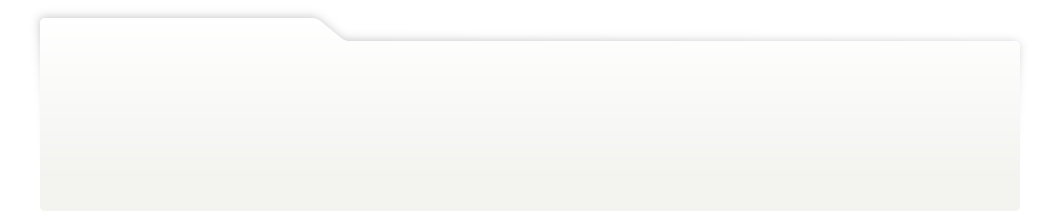
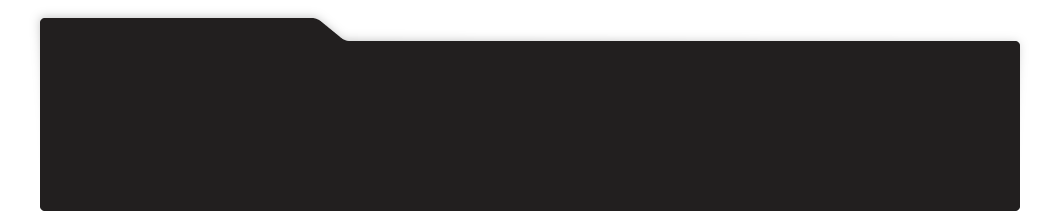
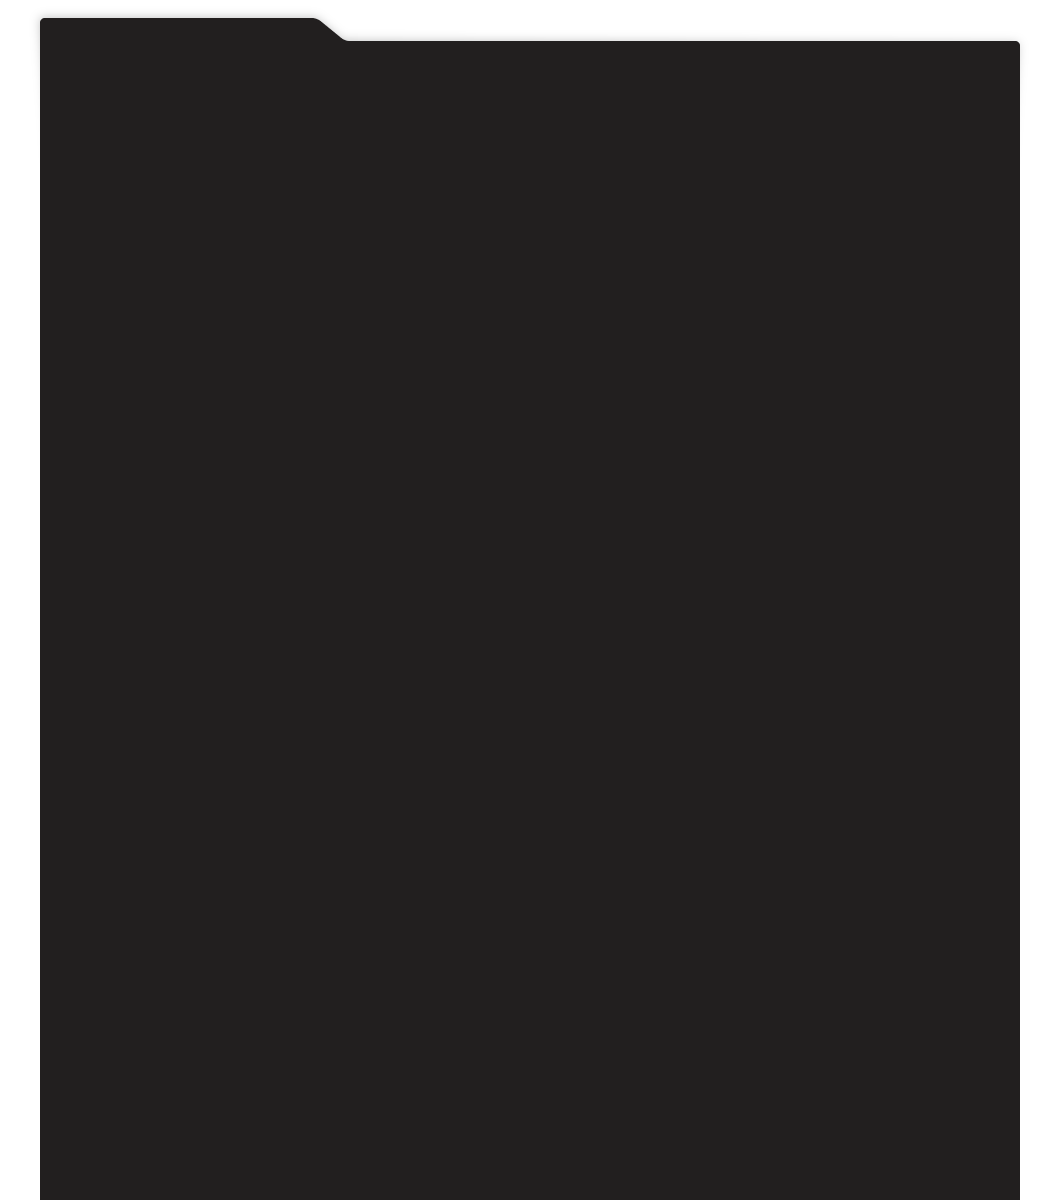
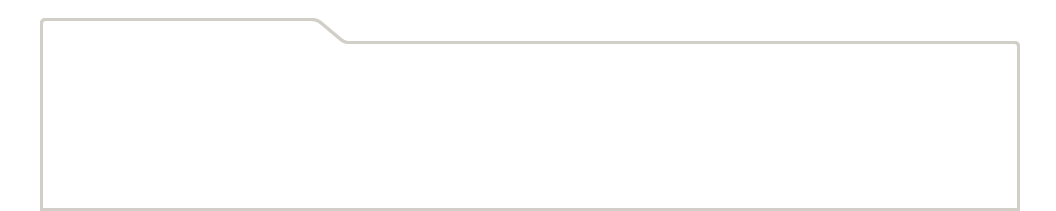
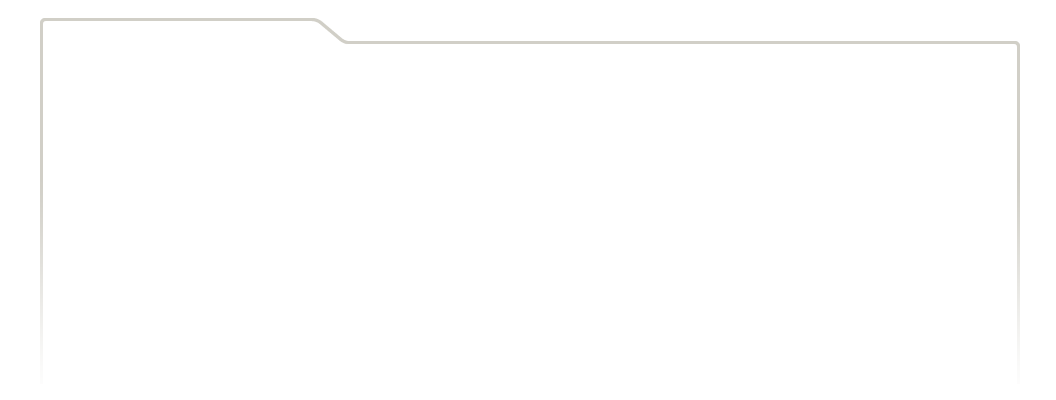
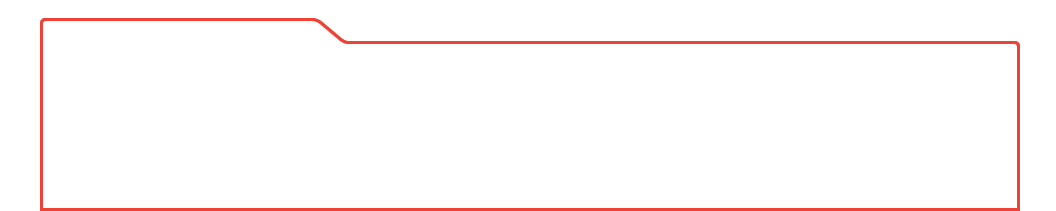
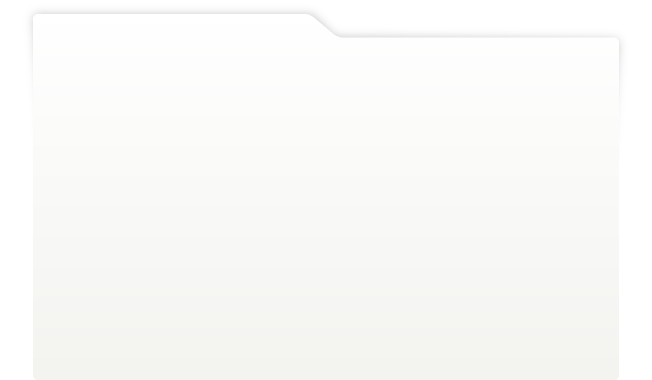
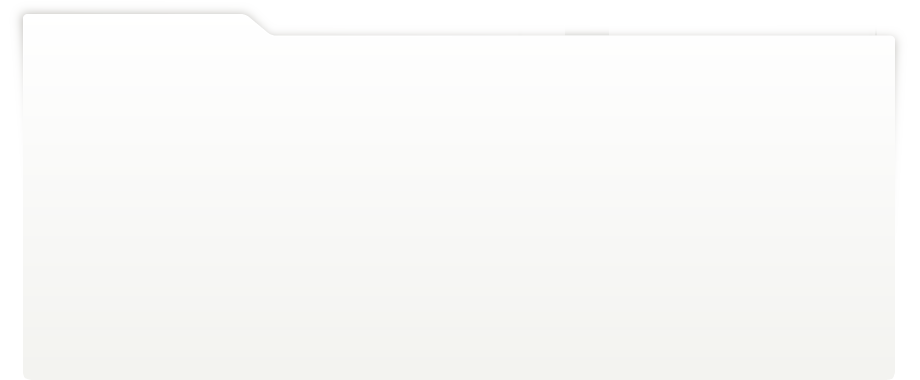
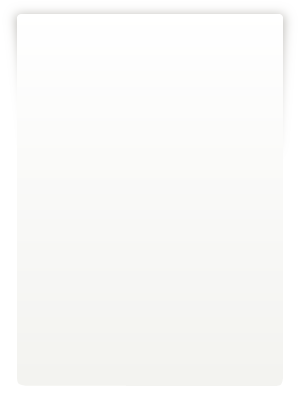
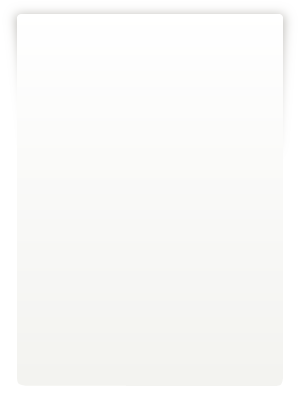
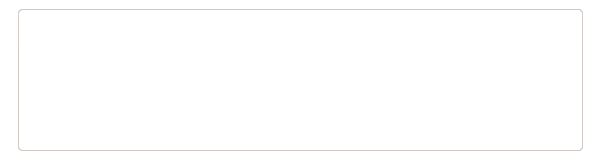
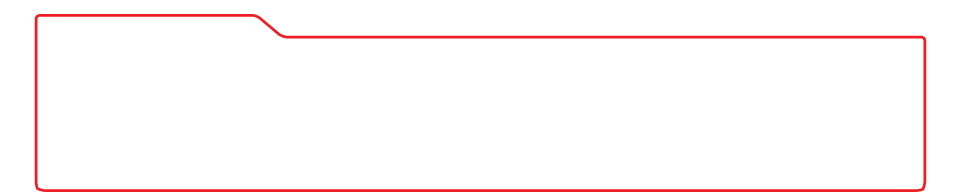
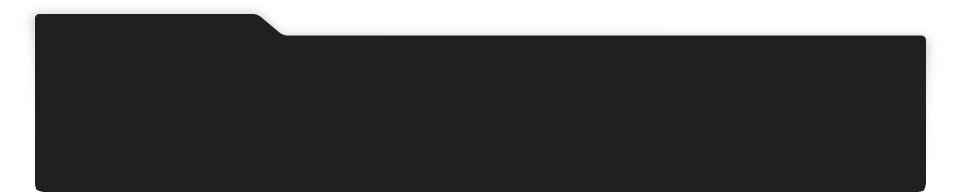
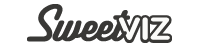
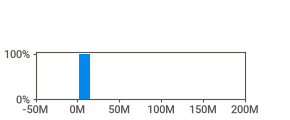
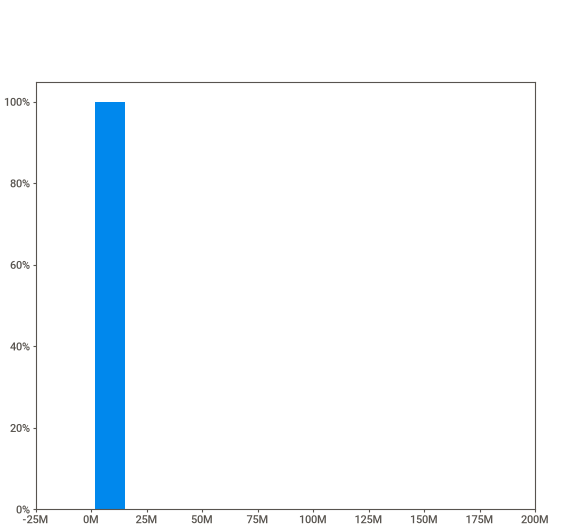
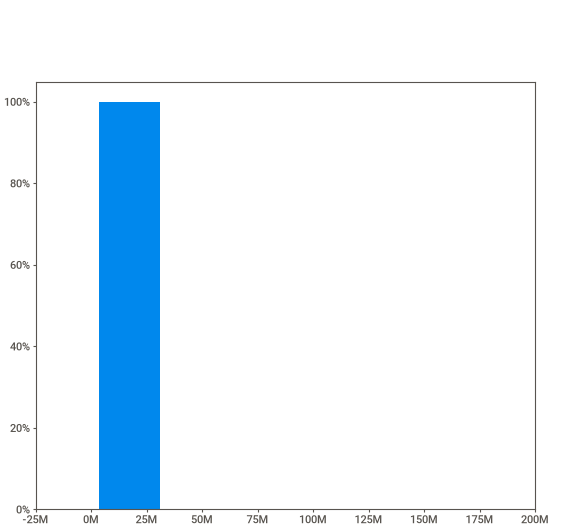
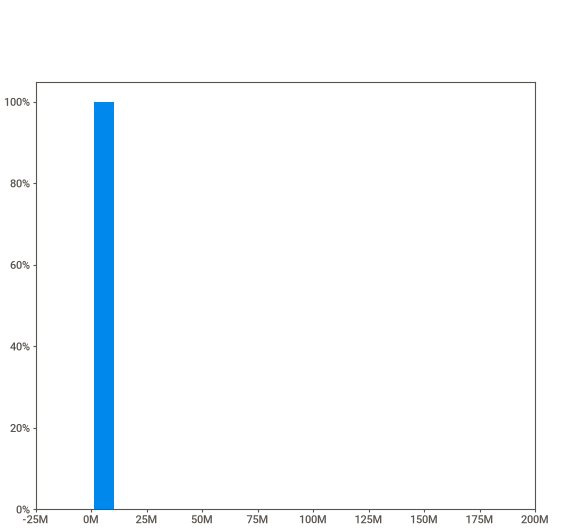
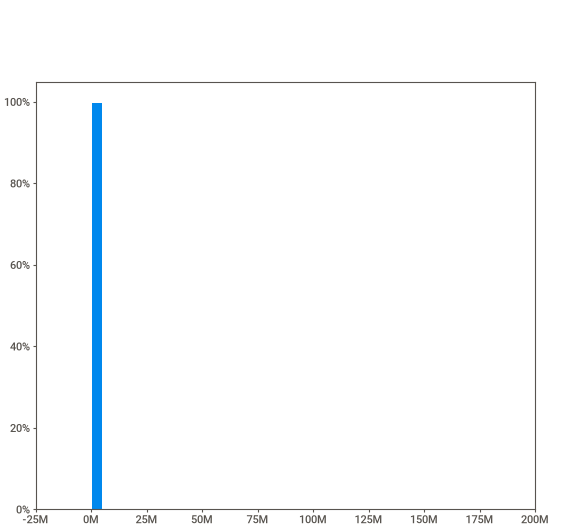
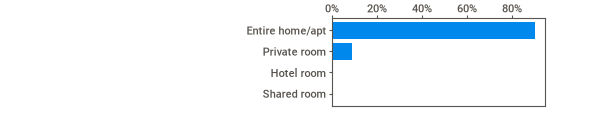
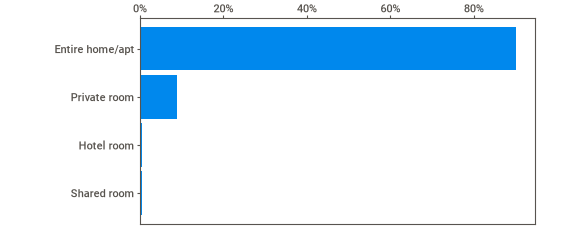
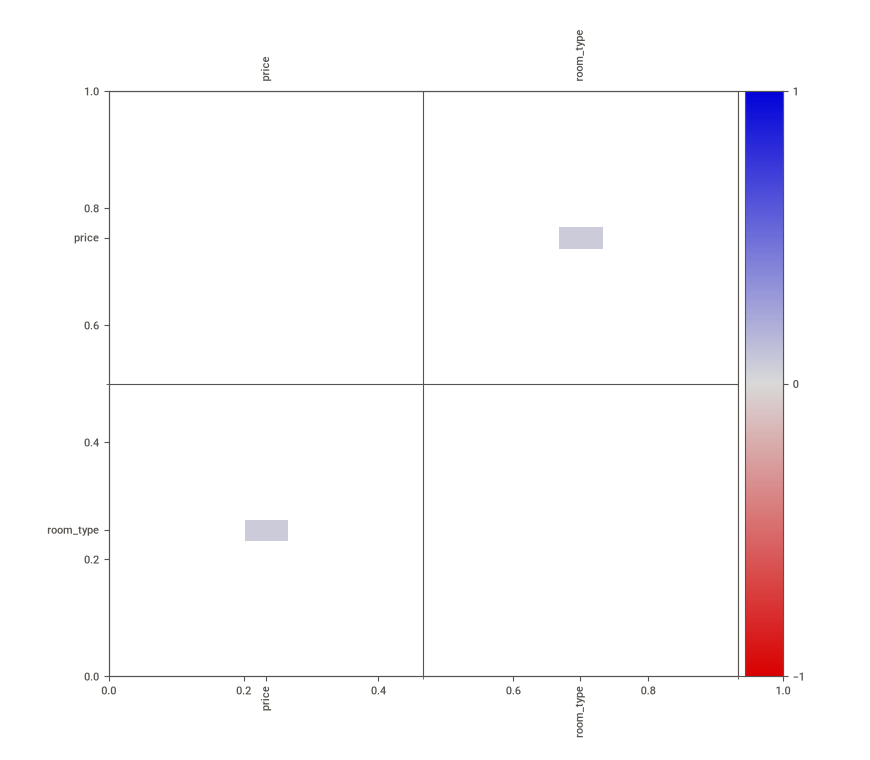
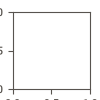

In [36]:
import sweetviz as sv

reporte = sv.analyze(dfB)
reporte.show_notebook()

### Vamos a indagar sobre duplicados.

In [37]:
print("Cantidad de filas duplicadas:", dfB.duplicated().sum())

Cantidad de filas duplicadas: 8029


### Vemos que la cantidad de duplicados es alta, pero esto puede deberse a que existan alquileres con exacto mismo precio y tipo de habitacion. Por esto vamos a sacarnos la duda utilizando los atributos 'latitude' y 'longitude'.

In [38]:
duplicados = dfB.join(dataset_limpio[["latitude", "longitude"]])
print("Cantidad de duplicados utilizando coordenadas del alquiler", duplicados.duplicated().sum())
print("Porcentaje duplicados reales: ", round((duplicados.duplicated().sum()/ len(dfB))*100,2) , "%")

Cantidad de duplicados utilizando coordenadas del alquiler 249
Porcentaje duplicados reales:  0.89 %


In [39]:
# Chequeamos con todas las columnas originales, para despejar todas las dudas
print("Cantidad de filas duplicadas con todas las columnas:", dataset_limpio.duplicated().sum())

Cantidad de filas duplicadas con todas las columnas: 5


### Con esto dejamos en claro que los duplicados que ya habiamos encontrado eran simplemente coincidencias de tipo y precio. Por ende, no se modificaran o eliminaran filas duplicadas, ya que, los duplicados reales representan menos del 1% de la muestra. Seguimos trabajando con el datafram 'dfB'.

In [40]:
dfB.sort_values("price").tail(10)

,price,room_type
id,,
1715206674581824021,103854017.5,Entire home/apt
1099478715504968920,110269755.0,Entire home/apt
1171679736496714320,117971864.0,Entire home/apt
1593615287549421619,118540097.0,Entire home/apt
1693690429819868240,119163498.4,Entire home/apt
1693702447946194916,119163498.4,Entire home/apt
568616064324992190,128501556.0,Private room
1554424397955633364,129721451.0,Entire home/apt
1048051998916469708,169983305.0,Private room


### A continuacion dejamos un resumen del EDA para los tipos de alquiler

In [49]:
import scipy.stats as stats
def resumen_eda(df, col_grupo, col_valor):
    filas=[]
    for grupo,sub in df.groupby(col_grupo):
        s = sub[col_valor]
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr
        outliers = ((s<limite_inf) | (s>limite_sup)).sum()
        resumen={
            'Grupo': grupo,
            'n': len(s),
            'Media': s.mean(),
            'Mediana': s.median(),
            'Desv. Est.': s.std(),
            'IQR': iqr,
            'CV (%)': (s.std(ddof=1)/s.mean())*100,
            'Asimetria': stats.skew(s, bias=False),
            'Curtosis': stats.kurtosis(s, bias=False),
            'Outliers': outliers,
            '% Outliers': (outliers/len(s))*100
        }
        filas.append(resumen)

    return pd.DataFrame(filas).round(2)

tabla_eda = resumen_eda(dfB, 'room_type', 'price')
print(tabla_eda.to_string(index=False))

          Grupo     n     Media  Mediana  Desv. Est.       IQR  CV (%)  Asimetria  Curtosis  Outliers  % Outliers
Entire home/apt 25141 254476.12 103977.0  3199412.01  63784.17 1257.25      32.15   1147.17      2089        8.31
     Hotel room   136 226311.80 222895.5   103051.50 139138.75   45.54       0.15     -0.00         0        0.00
   Private room  2485 500523.15  51002.0  6600215.16  45015.71 1318.66      17.38    331.70       205        8.25
    Shared room   131 163495.94  25405.0  1476709.39  21127.91  903.21      11.44    130.94         9        6.87


In [50]:
def resumen_eda_sin_outliers(df, col_grupo, col_valor):
    filas=[]
    for grupo,sub in df.groupby(col_grupo):
        q1 = sub[col_valor].quantile(0.25)
        q3 = sub[col_valor].quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - 1.5 * iqr
        limite_sup = q3 + 1.5 * iqr
        sub_limpio = sub[(sub[col_valor]>=limite_inf) & (sub[col_valor]<=limite_sup)]
        filas.append(sub_limpio)
        print(f"{grupo}: limite superior de tukey: {limite_sup:,.2f} |" 
              f"Outliers eliminados: = {len(sub) - len(sub_limpio)} ({((len(sub) - len(sub_limpio))/len(sub))*100:.2f}%)")

    return pd.concat(filas,ignore_index=True)

dfB_sin_outliers = resumen_eda_sin_outliers(dfB, 'room_type', 'price')
tabla_sin_ol = resumen_eda(dfB_sin_outliers, 'room_type', 'price')

print(tabla_sin_ol.to_string(index=False))

Entire home/apt: limite superior de tukey: 239,617.76 |Outliers eliminados: = 2089 (8.31%)
Hotel room: limite superior de tukey: 515,927.38 |Outliers eliminados: = 0 (0.00%)
Private room: limite superior de tukey: 147,679.03 |Outliers eliminados: = 205 (8.25%)
Shared room: limite superior de tukey: 74,081.28 |Outliers eliminados: = 9 (6.87%)
          Grupo     n     Media   Mediana  Desv. Est.       IQR  CV (%)  Asimetria  Curtosis  Outliers  % Outliers
Entire home/apt 23052 107769.92  99670.63    42243.89  52450.22   39.20       0.81      0.43       665        2.88
     Hotel room   136 226311.80 222895.50   103051.50 139138.75   45.54       0.15     -0.00         0        0.00
   Private room  2280  55170.75  48116.00    27933.63  34855.04   50.63       1.04      0.64        76        3.33
    Shared room   122  30185.49  25317.00    13582.78  15344.50   45.00       1.04      0.15         6        4.92


### Limpiando los outliers utilizando los limites de los quartiles, notamos que ahora las media y mediana son mas acordes entre si. Los outliers de este dataset pueden estar por diversas razones, tanto precios mal cargados, como precios altos para congelar el alquiler (Ejemplo: Un alquiler de espacio completo tenia como precio aproximadamente 170 millones la noche, este lo podemos tomar como un outlier extremo, el cual, casi con certeza, es un valor que no refleja nada real).

### Ahora vemos que la Media de espacios enteros es menos de 2 veces mayor a la Media de las habitaciones privadas (107769 < 2x55170). Y con la mediana, donde para los espacios enteros es de 99670, mientras que la de las habitaciones privadas es de 48116, la diferencia es de menos del doble (99670 > 2x48116).

### Con esto hecho, se tomo la decision de utilizar dfB_sin_outliers, este dataframe esta limpio de los outliers que nos afectaban las estadisticas previas.

## TO-DO: Visualizacion de los datos, validacion de la hipotesis con test correspondientes

In [51]:
dfB_sin_outliers.describe()

,price
count,25590.000000
mean,103343.589714
std,45433.944016
min,1215.500000
25%,72987.640000
50%,95960.995000
75%,126963.500000
max,509213.330000


/tmp/ipykernel_3368/387207214.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Tipo",
findfont: Failed to find font weight normal for Roboto, now using 500.


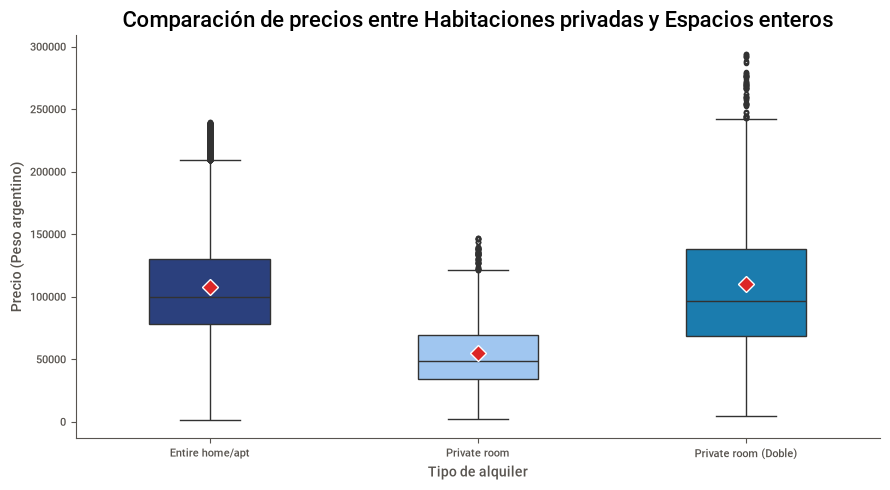

In [53]:
df_espacio_entero = pd.DataFrame({
    "Tipo": "Entire home/apt",
    "price": dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Entire home/apt", "price"]
})
df_habitacion_privada = pd.DataFrame({
    "Tipo": "Private room",
    "price": dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Private room", "price"]
})
df_habitacion_privada_doble = pd.DataFrame({
    "Tipo": "Private room (Doble)",
    "price": df_habitacion_privada["price"] * 2
})

df_box = pd.concat([df_espacio_entero, df_habitacion_privada, df_habitacion_privada_doble], ignore_index=True)

plt.figure(figsize=(9, 5))

sns.boxplot(x="Tipo", 
            y="price", 
            data=df_box, 
            palette=["#1e3a8a", "#93c5fd", "#0284c7"], 
            width=0.45, 
            showmeans=True, 
            meanprops={"marker": "D", "markerfacecolor": "#dc2626", "markeredgecolor": "white", "markersize": 8, "label": "Media"})

plt.title("Comparación de precios entre Habitaciones privadas y Espacios enteros", fontsize=16)
plt.xlabel("Tipo de alquiler")
plt.ylabel("Precio (Peso argentino)")
sns.despine()
plt.tight_layout()
plt.show()

### Lo que notamos visualmente es que, la mediana (Q2) de los espacios enteros se encuentra levemente por encima del doble de las habitaciones privadas, mientras que con la media (El rombo rojo dentro del box) ocurre al reves, la media de los espacios enteros esta levemente por debajo del doble de las habitaciones privadas.

## Vamos a dar paso los test para poder validar o rechazar la hipotesis de forma precisa.

### Test de shapiro-wilk para chequear normalidad:

In [58]:
alpha = 0.05

#Separamos entre espacio entero y habitacion privada
y_espacio_entero = dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Entire home/apt", "price"]
y_habitacion_privada = dfB_sin_outliers.loc[dfB_sin_outliers["room_type"] == "Private room", "price"]
y_habitacion_privada_doble = df_habitacion_privada * 2

#Test de shapiro-wilk para verificar normalidad
stat, p = stats.shapiro(y_espacio_entero)
print(f"Shapiro-Wilk test para 'Entire home/apt': estadístico={stat:.4f}, p-valor={p:.4e}")

stat, p = stats.shapiro(y_habitacion_privada)
print(f"Shapiro-Wilk test para 'Private room': estadístico={stat:.4f}, p-valor={p:.4e}")

Shapiro-Wilk test para 'Entire home/apt': estadístico=0.9533, p-valor=1.0842e-63
Shapiro-Wilk test para 'Private room': estadístico=0.9186, p-valor=2.1405e-33


/home/matilinux/Ciencia-De-Datos/TP_Fundamentos/TP_Fundamentos/TpEspecial/venvTPE/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23052.
  res = hypotest_fun_out(*samples, **kwds)


### Con esto rechazamos normalidad ya que ambos para ambos p no se cumple p > 0,05
### Ahora vamos a utilizar levene para chequear homocedasticidad.

//MULTIVARIADAS